# 02 · Los dos alelos de `BUB1B`, curación estilo ACMG

> **Saneado:** sin posición, sin identidad de aminoácidos, sin coordenadas. Los alelos se
> nombran por su papel (`truncante`, `missense`), que es lo que importa para la curación.
>
> **Esto es curación de investigación, no un informe clínico.** El entregable del proyecto es
> una hipótesis falsable, nunca una recomendación.

## Pregunta biológica

**¿Qué sostiene cada alelo por separado, y qué haría falta para que el par sea causal?**

## Hipótesis y preregistro

`docs/DECISIONS.md`. Los umbrales de `PP3` se sellaron **antes** de mirar REVEL, precisamente
para que un predictor no informativo no se sumara a conveniencia.

In [1]:
import sys, os, io, json, pickle, collections
os.chdir("..")                       # el pipeline usa rutas relativas a la raiz
sys.path.insert(0, ".")
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from src.nb import figlib as fl      # figuras inline + caption con procedencia
print("entorno listo · las figuras de este notebook aparecen INLINE, con caption")

entorno listo · las figuras de este notebook aparecen INLINE, con caption


In [2]:
fl.labels("Interpretacion", "Limite de la evidencia")

## Entradas, QC de las dos llamadas

Antes de curar nada: ¿son buenas las llamadas? Una curación sobre una llamada mala es ruido
con formato ACMG.

In [3]:
from src.paths import patient_vcf
from src.prioritization.genome_wide import load

rows = load("work/gw/highmod_ann.tsv", patient_vcf())
seen, alleles = set(), []
for v in rows:
    if v.gene != "BUB1B" or v.impact not in ("HIGH", "MODERATE"):
        continue
    k = (v.loc, v.allele)
    if k in seen:
        continue
    seen.add(k); alleles.append(v)

ROLE = {"HIGH": "alelo A · truncante", "MODERATE": "alelo B · missense"}
# El campo GT crudo NO se imprime: es el genotipo del paciente en el formato
# exacto que la regla dura prohibe versionar. La cigosidad si se dice, en
# palabras, porque ya es la afirmacion canonica del proyecto. Lo demas son
# metricas de calidad de la llamada, que es lo que este QC evalua.
ZYG = {"0/1": "heterocigoto", "1|0": "heterocigoto", "0|1": "heterocigoto",
       "1/1": "homocigoto alternativo"}
for v in alleles:
    ab = v.allele_balance
    print(f"  {ROLE.get(v.impact, v.impact):<24} {ZYG.get(v.gt, 'cigosidad no resuelta'):<14}"
          f"DP={v.dp}  GQ={v.gq}  AB={ab:.2f}  FILTER={v.filt}  MAX_AF="
          f"{('%.2e' % v.max_af) if v.max_af is not None else 'AUSENTE'}")

  alelo A · truncante      heterocigoto  DP=46  GQ=99  AB=0.54  FILTER=PASS  MAX_AF=9.98e-05
  alelo B · missense       heterocigoto  DP=28  GQ=99  AB=0.46  FILTER=PASS  MAX_AF=AUSENTE


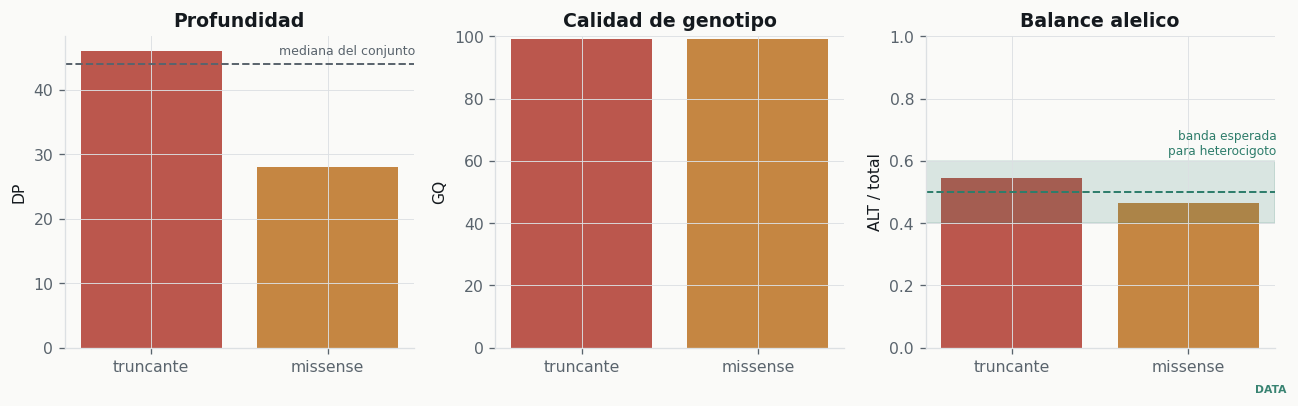

> **Figura QC · las dos llamadas, antes de curar nada**  
> `EXP-007` · figure class `DATA`, figura cientifica · evidence origin `MEASURED`  
> *Interpretacion.* profundidad por encima de la mediana del conjunto, GQ maxima y balance alelico dentro de la banda esperada para heterocigotos en ambos alelos. Las llamadas son solidas.  
> **Limite de la evidencia.** que buenas llamadas impliquen causalidad. El balance alelico sirve para QC y mosaicismo; NO establece que los alelos esten en trans.  
> procedencia: `VCF del paciente, cruzado por identidad de alelo`

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(11.0, 3.4))
labels = [ROLE.get(v.impact, v.impact).split("·")[1].strip() for v in alleles]
cols = [fl.DEAD if v.impact == "HIGH" else fl.OPEN for v in alleles]

axes[0].bar(labels, [v.dp for v in alleles], color=cols, alpha=0.9)
axes[0].axhline(44, color=fl.SOFT, ls="--", lw=1.2)
axes[0].text(1.5, 45.5, "mediana del conjunto", fontsize=7.6, color=fl.SOFT, ha="right")
axes[0].set_title("Profundidad"); axes[0].set_ylabel("DP")

axes[1].bar(labels, [v.gq for v in alleles], color=cols, alpha=0.9)
axes[1].set_ylim(0, 100); axes[1].set_title("Calidad de genotipo"); axes[1].set_ylabel("GQ")

abs_ = [v.allele_balance for v in alleles]
axes[2].bar(labels, abs_, color=cols, alpha=0.9)
axes[2].axhspan(0.40, 0.60, color=fl.ALIVE, alpha=0.16)
axes[2].axhline(0.5, color=fl.ALIVE, ls="--", lw=1.2)
axes[2].set_ylim(0, 1); axes[2].set_title("Balance alelico"); axes[2].set_ylabel("ALT / total")
axes[2].text(1.5, 0.62, "banda esperada\npara heterocigoto", fontsize=7.4, color=fl.ALIVE,
             ha="right")

fl.done(fig, "Figura QC · las dos llamadas, antes de curar nada", "EXP-007", "MEASURED",
        "DATA",
        "profundidad por encima de la mediana del conjunto, GQ maxima y balance alelico "
        "dentro de la banda esperada para heterocigotos en ambos alelos. Las llamadas son "
        "solidas.",
        "que buenas llamadas impliquen causalidad. El balance alelico sirve para QC y "
        "mosaicismo; NO establece que los alelos esten en trans.",
        prov="VCF del paciente, cruzado por identidad de alelo")

## Resultado primario 1 · la anatomía del gen, con todo ClinVar encima

La curación necesita saber **dónde** cae cada alelo dentro del gen. Hasta ahora eso se dibujaba
a mano. Aquí el modelo de transcrito y los dominios vienen de **Ensembl REST**, y el paisaje de
variantes son los **1 497 registros missense de ClinVar** para este gen, uno a uno.

> La petición a Ensembl lleva únicamente el símbolo `BUB1B`. **Ningún dato del paciente sale de
> la máquina.** Las posiciones del caso entran solo como marcas sobre el eje, sin número.

In [5]:
from src.structure.transcript_model import fetch
T = fetch()                                   # cacheado en work/struct/transcript.json
L = T["translation"]["length"]
DOM = [d for d in T["domains"] if d["type"] in ("Pfam", "Gene3D")]
EX  = [e for e in T["exons"] if e.get("aa")]

print(f"  Ensembl release {T['release']} · {T['transcript']} [{T['transcript_pick']}]")
print(f"  {T['n_exons']} exones · proteina {L} aa · CDS {T['translation']['cds_len']:,} nt")
for d in DOM:
    print(f"    {d['type']:<8}{d['start']:>5}-{d['end']:<5} {d['desc'][:52]}")

cv = json.load(io.open("work/clinvar/landscape_missense.json", encoding="utf-8"))
tot = cv["totals"]
per = collections.defaultdict(collections.Counter)
for v in cv["variants"]:
    per[v["pos"]][v["cls"]] += 1
print()
print(f"  ClinVar missense en el gen: {len(cv['variants']):,} registros "
      f"sobre {len(per):,} residuos distintos")
for k, v in tot.items():
    print(f"    {k:<8}{v:>6}  ({100*v/sum(tot.values()):.1f} %)")

  Ensembl release 116 · ENST00000287598 [canonical]
  23 exones · proteina 1050 aa · CDS 3,153 nt
    Gene3D     46-203   
    Pfam       57-179   Mad3/Bub1 homology region 1
    Gene3D    782-1042  Transferase(Phosphotransferase) domain 1

  ClinVar missense en el gen: 1,497 registros sobre 835 residuos distintos
    P/LP         1  (0.1 %)
    B/LB        35  (2.4 %)
    VUS       1426  (97.5 %)


### Figura principal 1 · navegador del gen, exones, dominios y ClinVar

C:\Users\USUARIO\Downloads\mosaic-rescue\src\figures\fig02_browser.py:152: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0.040, 1, 1), h_pad=1.0)


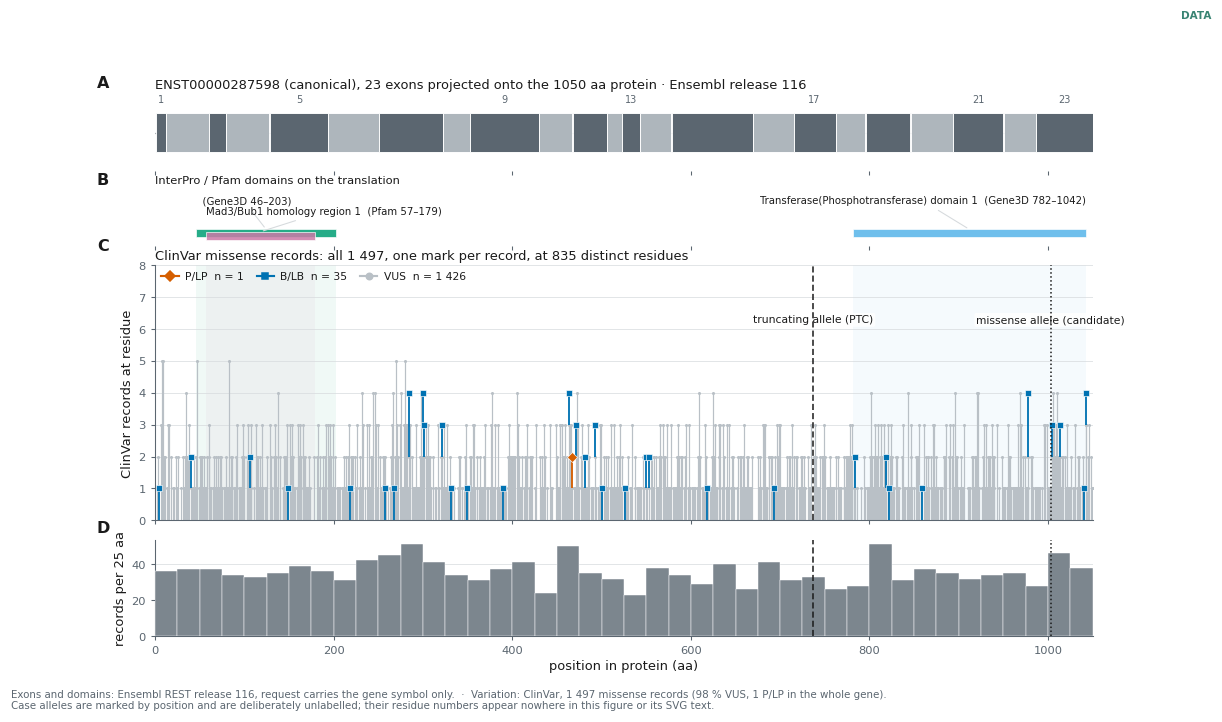

> **Figura principal 1 · navegador del gen, exones, dominios y ClinVar**  
> `EXP-007` · figure class `DATA`, figura cientifica · evidence origin `EXTERNAL`  
> *Interpretacion.* la anatomia real del transcrito canonico (23 exones, 1050 aa), los dominios que Ensembl anota sobre la traduccion, y las 1,497 missense que ClinVar tiene registradas en el gen, una por registro. 98 % son VUS y hay UNA sola P/LP en todo el gen: no existe hotspot demostrable en ninguna parte, y por eso PM1 no aplica aqui ni en ningun otro punto. El panel D convierte los 1 497 registros en una distribucion legible; las dos guias verticales situan los alelos del caso en esa anatomia.  
> **Limite de la evidencia.** que estar dentro de un dominio sea patogenicidad. La densidad de ClinVar refleja sobre todo cuanto se ha secuenciado y reportado el gen, no donde estan las mutaciones que importan; y la ausencia de hotspot NO es evidencia contra el candidato.  
> datos: `Ensembl REST release 116 + work/clinvar/landscape_missense.json (1 497 registros)` · libreria: `dna_features_viewer + matplotlib` · procedencia: `figures/pub/fig02_gene_browser.svg + .png 300 dpi`

In [6]:
from src.figures import fig02_browser as FB

g = json.load(io.open("work/struct/fig3_exons.json", encoding="utf-8"))
fig = FB.build(T, cv, {"ptc_aa": g["ptc_cds"] // 3 + 1, "mis_aa": g["mis_cds"] // 3 + 1})
fl.pub(fig, "Figura principal 1 · navegador del gen, exones, dominios y ClinVar",
       "EXP-007", "EXTERNAL", "DATA",
       f"la anatomia real del transcrito canonico ({T['n_exons']} exones, {L} aa), los "
       f"dominios que Ensembl anota sobre la traduccion, y las {len(cv['variants']):,} "
       f"missense que ClinVar tiene registradas en el gen, una por registro. "
       f"{100*tot['VUS']/sum(tot.values()):.0f} % son VUS y hay UNA sola P/LP en todo el gen: "
       f"no existe hotspot demostrable en ninguna parte, y por eso PM1 no aplica aqui ni en "
       f"ningun otro punto. El panel D convierte los 1 497 registros en una distribucion "
       f"legible; las dos guias verticales situan los alelos del caso en esa anatomia.",
       "que estar dentro de un dominio sea patogenicidad. La densidad de ClinVar refleja "
       "sobre todo cuanto se ha secuenciado y reportado el gen, no donde estan las mutaciones "
       "que importan; y la ausencia de hotspot NO es evidencia contra el candidato.",
       source="Ensembl REST release " + str(T["release"]) +
              " + work/clinvar/landscape_missense.json (1 497 registros)",
       lib="dna_features_viewer + matplotlib", slug="fig02_gene_browser")

## Resultado primario 2 · el paisaje de missense en ClinVar

`PM1`, `PS1` y `PM5` se evalúan sobre la clase comparable. El error que esto corrigió: contar
«0 P/LP frente a 35 B/LB» mezclaba todas las consecuencias, **31 de esas 35 eran sinónimas**.

In [7]:
d = json.load(io.open("work/clinvar/landscape_missense.json", encoding="utf-8"))
tot = d["totals"]
print("  ClinVar sobre TODO el gen, solo missense:")
for k, v in tot.items():
    print(f"    {k:<14}{v:>6}")
print()
print(f"  -> {100*tot.get('VUS',0)/sum(tot.values()):.0f} % son VUS. Ningun punto del gen")
print("     tiene hotspot demostrable, asi que PM1 no aplica en NINGUNA parte.")

  ClinVar sobre TODO el gen, solo missense:
    P/LP               1
    B/LB              35
    VUS             1426

  -> 98 % son VUS. Ningun punto del gen
     tiene hotspot demostrable, asi que PM1 no aplica en NINGUNA parte.


## Resultado primario 3 · geometría de NMD y de la fase

Dos medidas geométricas deciden dos cosas distintas: si el truncante activa NMD, y si los dos
alelos pueden conectarse con lecturas cortas.

In [8]:
g = json.load(io.open("work/struct/fig3_exons.json", encoding="utf-8"))
ptc, last = g["ptc_cds"], g["last_junction"]
margin = last - ptc
print(f"  distancia del PTC a la ultima union exon-exon : {margin:,} nt")
print(f"  umbral de la regla 50-55 nt                   : 50-55 nt")
print(f"  margen                                        : ~{margin/52:.0f}x el umbral")
print()
print("  -> NMD predicho con holgura. PVS1 candidato, con el arbol de decision recorrido.")

  distancia del PTC a la ultima union exon-exon : 748 nt
  umbral de la regla 50-55 nt                   : 50-55 nt
  margen                                        : ~14x el umbral

  -> NMD predicho con holgura. PVS1 candidato, con el arbol de decision recorrido.


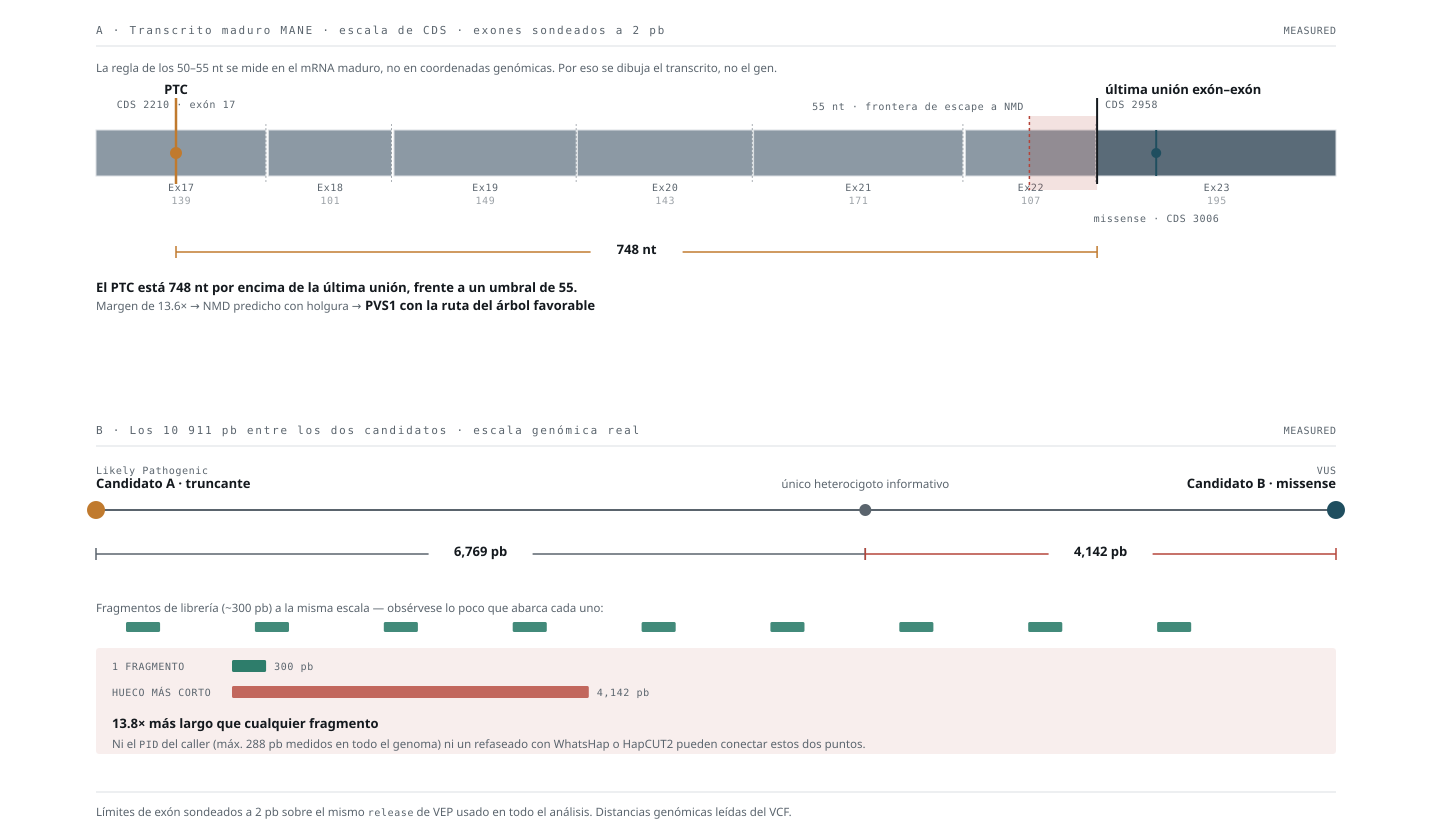

> **Figura principal 3 · geometria de NMD y de la fase**  
> `EXP-007 · EXP-013` · figure class `DATA`, figura cientifica · evidence origin `MEASURED+DERIVED`  
> *Interpretacion.* el PTC cae a ~748 nt de la ultima union exon-exon, muy por encima del umbral de 50-55 nt: NMD predicho con holgura. Y abajo, por que la fase no se resuelve: el hueco entre los dos alelos es de ~11 kb frente a fragmentos de ~300 pb, con un solo heterocigoto intermedio.  
> **Limite de la evidencia.** que los dos alelos esten en trans. `unphased` no es `trans`: el bloque de fase mas largo de todo el genoma mide 288 pb. La fase no resuelta PERMANECE no resuelta.  
> libreria: `SVG` · procedencia: `src/make_fig3.py genera fig3_phase.svg, sha256[:12]=c20e1536c662`

In [9]:
fl.svg("figures/fig3_phase.svg",
       "Figura principal 3 · geometria de NMD y de la fase",
       "EXP-007 · EXP-013", "MEASURED+DERIVED", "DATA",
       f"el PTC cae a ~{margin:,} nt de la ultima union exon-exon, muy por encima del umbral "
       "de 50-55 nt: NMD predicho con holgura. Y abajo, por que la fase no se resuelve: el "
       "hueco entre los dos alelos es de ~11 kb frente a fragmentos de ~300 pb, con un solo "
       "heterocigoto intermedio.",
       "que los dos alelos esten en trans. `unphased` no es `trans`: el bloque de fase mas "
       "largo de todo el genoma mide 288 pb. La fase no resuelta PERMANECE no resuelta.",
       generator="src/make_fig3.py")

## Robustez · el techo de cada alelo, y qué lo movería

La curación no termina en una etiqueta: termina sabiendo **cuánta evidencia falta y de qué
tipo**.

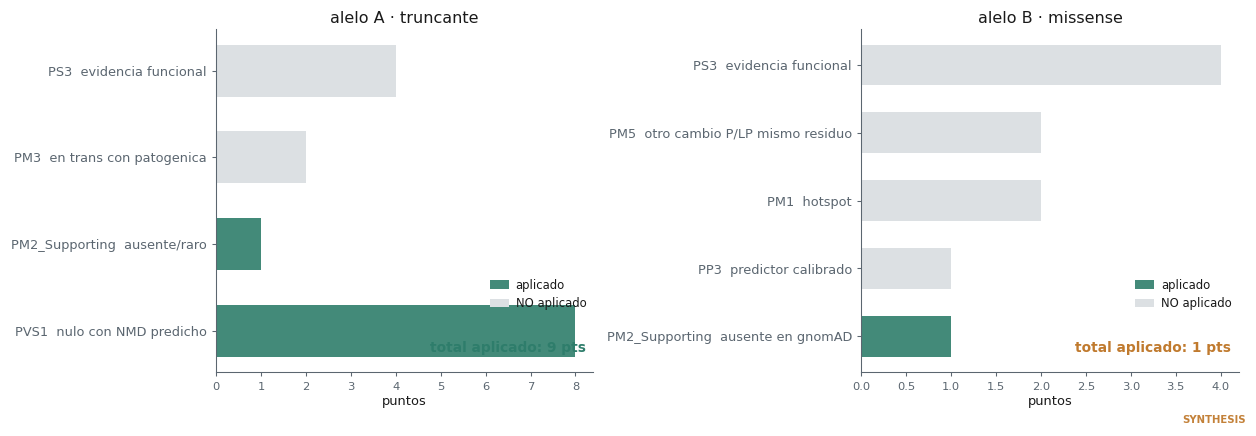

> **Figura de robustez · puntos ACMG aplicados y los que faltan**  
> `EXP-007` · figure class `SYNTHESIS`, no es un dato: synthesis · evidence origin `DERIVED`  
> *Interpretacion.* el truncante suma 9 puntos (PVS1 + PM2_Supporting) y llega a Likely Pathogenic. El missense suma 1: se queda en VUS, y seguiria en VUS aunque entrara PP3, porque el maximo alcanzable con PM1+PM5 son 5 puntos y VUS llega hasta 5.  
> **Limite de la evidencia.** que los puntos no aplicados sean evidencia en contra. PM3 esta bloqueado por DECISION, mas conservador que ClinGen; PP3 no aplica porque REVEL dio 0,472, por debajo del umbral SELLADO ANTES de mirarlo.  
> procedencia: `docs/ACMG_CURATION.md · umbrales preregistrados en DECISIONS.md`

In [10]:
# Puntos del marco bayesiano de ClinGen, tal y como se aplicaron
EVID = {
 "alelo A · truncante": [("PVS1  nulo con NMD predicho", 8, True),
                          ("PM2_Supporting  ausente/raro", 1, True),
                          ("PM3  en trans con patogenica", 2, False),
                          ("PS3  evidencia funcional", 4, False)],
 "alelo B · missense": [("PM2_Supporting  ausente en gnomAD", 1, True),
                         ("PP3  predictor calibrado", 1, False),
                         ("PM1  hotspot", 2, False),
                         ("PM5  otro cambio P/LP mismo residuo", 2, False),
                         ("PS3  evidencia funcional", 4, False)],
}
fig, axes = plt.subplots(1, 2, figsize=(11.4, 3.9))
for ax, (name, items) in zip(axes, EVID.items()):
    ys = range(len(items))
    got = [p if ok else 0 for _, p, ok in items]
    miss = [0 if ok else p for _, p, ok in items]
    ax.barh(list(ys), got, color=fl.ALIVE, alpha=0.9, height=0.6, label="aplicado")
    ax.barh(list(ys), miss, color=fl.RULE, height=0.6, label="NO aplicado")
    ax.set_yticks(list(ys)); ax.set_yticklabels([t for t, _, _ in items], fontsize=8.4)
    ax.set_xlabel("puntos"); ax.set_title(name, fontsize=10.5)
    ax.axvline(0, color=fl.INK, lw=1)
    total = sum(got)
    ax.text(0.98, 0.06, f"total aplicado: {total} pts", transform=ax.transAxes,
            ha="right", fontsize=9, fontweight="bold",
            color=fl.ALIVE if total >= 6 else fl.OPEN)
    ax.legend(fontsize=7.6, frameon=False, loc="lower right", bbox_to_anchor=(1, 0.16))

fl.done(fig, "Figura de robustez · puntos ACMG aplicados y los que faltan",
        "EXP-007", "DERIVED", "SYNTHESIS",
        "el truncante suma 9 puntos (PVS1 + PM2_Supporting) y llega a Likely Pathogenic. El "
        "missense suma 1: se queda en VUS, y seguiria en VUS aunque entrara PP3, porque el "
        "maximo alcanzable con PM1+PM5 son 5 puntos y VUS llega hasta 5.",
        "que los puntos no aplicados sean evidencia en contra. PM3 esta bloqueado por "
        "DECISION, mas conservador que ClinGen; PP3 no aplica porque REVEL dio 0,472, por "
        "debajo del umbral SELLADO ANTES de mirarlo.",
        prov="docs/ACMG_CURATION.md · umbrales preregistrados en DECISIONS.md")

## Evidencia contradictoria, declarada

**SIFT `deleterious` 0,01 y PolyPhen 0,997 apuntaban fuerte a patogenicidad.** El predictor
calibrado dice que no hay evidencia asignable. Sumar los dos primeros habría dado un `PP3`
injustificado, **se ve el tamaño del error que el preregistro evitó**.

Y un error propio: afirmé que ninguna candidata estaba en dbSNP, deduciéndolo de la columna
`ID` vacía del VCF. **Falso**: esa columna solo indica que el caller no anotó. El truncante sí
está, y en ClinVar como patogénico.

## Decisión

| | |
|---|---|
| **Alelo A · truncante** | **Likely Pathogenic** (9 pts) |
| **Alelo B · missense** | **VUS**, y sigue VUS aunque entrara `PP3` |
| **El par** | *one likely pathogenic truncating allele + one rare missense candidate, **phase unresolved*** |

### Qué NO establece

**No es heterocigosis compuesta demostrada.** `PM3` sigue bloqueado, la fase sigue sin
resolver, y sin eso el modelo bialélico es *candidato*, no establecido.

### Falsificador

Genotipos parentales, o lectura larga dirigida sobre los ~11 kb que separan los dos alelos.
Cualquiera de los dos convierte «candidato» en resuelto, **en la dirección que sea**.

### Siguiente experimento

`03_BUBR1_MECHANISM`, si el missense no se mueve por clasificación, ¿se mueve por mecanismo?